# Trabajo practico especial

**GRUPO 18**

**integrantes**:
+ Candela Belen, Buggarini.
+ Nubia Amarena, Larios.
+ Ignacio, Quiñoneros.

## Analisis exploratorio de los datos

In [31]:
import pandas as pd
from os import path, listdir

df_calendar=pd.read_csv("calendar.csv.gz")
df_listings = pd.read_csv("listings (1).csv.gz")

# chequeamos si los archivos están en el directorio donde estamos parados
lista_archivos = listdir("./")
print(f"El contenido de la carpeta es: {lista_archivos}")

El contenido de la carpeta es: ['.git', '.gitignore', 'Azucar', 'calendar.csv.gz', 'entrega.ipynb', 'Entregaf.ipynb', 'HipotesisCande.ipynb', 'listings (1).csv.gz', 'prueba1.ipynb', 'prueba2.ipynb', 'prueba3.ipynb', 'prueba4.ipynb', 'pruebanub.ipynb', 'README.md', 'requirements.txt', 'tabla_cruzada.png', 'TPE_CienciaDeDatos']


**implementación de operaciones de limpieza de la base**

Primero separamos el dataset original para realizar el pre procesamiento de los datos.

Prepocesamientos que se realizaron:
+ En primera instancia eliminamos todas las columnas que tengan en su totalidad nulos, estas estan casi en su totalidad a informacion del host.
+ Tranformamos las variables dictomicas `source`, `has_availability`, `host_is_superhost`, `host_has_profile_pic` y `host_identify_verified`.
+ Limpiamos de caracteres la variable `price`

In [97]:
#copiamos el conjunto para preservarlo
preprocessed_dataset = df_listings.copy()

#borramos columnas con todos sus valores nulos
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_about',axis=1)

#transformacion de variables a dicotomicas
preprocessed_dataset ['source']= preprocessed_dataset['source'].map({"city scrape": True, "previous scrape": False})
preprocessed_dataset ['has_availability']= preprocessed_dataset['has_availability'].map({"t": True, "f": False}).fillna(False).astype(bool)
preprocessed_dataset ['host_is_superhost']= preprocessed_dataset['host_is_superhost'].map({"t": True, "f": False})
preprocessed_dataset ['host_has_profile_pic']= preprocessed_dataset['host_has_profile_pic'].map({"t": True, "f": False})
preprocessed_dataset ['host_identity_verified']= preprocessed_dataset['host_identity_verified'].map({"t": True, "f": False})

preprocessed_dataset['price'] = preprocessed_dataset['price'].str.replace(r'[$,]', '', regex=True).astype(float)

#Imputamos por la mediana
preprocessed_dataset['price'] = preprocessed_dataset['price'].fillna(preprocessed_dataset['price'].median())
#sacamos los outliers de precio
# 1. Calculamos los límites basados en los percentiles 1 y 99
lo, hi = preprocessed_dataset["price"].quantile([.01, .99])
print("Rango conservado:", lo, "-", hi)

# 2. Limpiamos outliers y actualizamos el DataFrame
preprocessed_dataset = preprocessed_dataset[preprocessed_dataset["price"].between(lo, hi)].copy()

Rango conservado: 22926.3008 - 776463.2999999998


In [98]:

#Queremos ver el tipo de alojamiento al que pertenece y vamos a imputar por la mediana de los precios de ese tipo de alojamiento para no tener nulos y evitar eliminar filas

# Cantidad y porcentaje de nulos
print(preprocessed_dataset["price"].isna().sum())
print(preprocessed_dataset["price"].isna().mean() * 100)
nulos = preprocessed_dataset[preprocessed_dataset["price"].isna()]

# Nulos por tipo de alojamiento
print(preprocessed_dataset.groupby("room_type")["price"].apply(lambda s: s.isna().sum()))
preprocessed_dataset["price"] = preprocessed_dataset["price"].fillna(
    preprocessed_dataset.groupby("room_type")["price"].transform("median")
)

preprocessed_dataset["price"].info()

0
0.0
room_type
Entire home/apt    0
Hotel room         0
Private room       0
Shared room        0
Name: price, dtype: int64
<class 'pandas.Series'>
Index: 29091 entries, 0 to 29684
Series name: price
Non-Null Count  Dtype  
--------------  -----  
29091 non-null  float64
dtypes: float64(1)
memory usage: 454.5 KB


In [99]:
preprocessed_dataset['price'].describe()

count     29091.000000
mean     121309.100656
std       83034.482582
min       22935.120000
25%       77245.000000
50%      100631.330000
75%      135469.000000
max      776253.500000
Name: price, dtype: float64

## 1 Hipotesis univariada (catedra):

### Analisis exploratorio:

Comenzamos identificando la variable que queriamos analizar. En este caso, como habíamos visto en el EDA, la variable room_type mostraba su mayor concentración en entire_home/apt, al querer incluir los demás tipos de habitación nos encontramos con un problema, no teníamos forma de saber si un host podía alquilar múltiples habitaciones en su propia casa, si múltiples habitaciones de hotel corresponden al mismo hotel, y si era un solo hotel pero pequeño, ¿se considera multipropiedad?, lo mismo con shared_rooms, podía ser parte de un hostel, de alguien alquilando habitaciones en su casa, entonces como no tenemos datos certeros para saber esto, decidimos no incluirlas en el análisis y solo quedarnos con entire home/apt, entonces si un mismo host tenia mas de dos casas o departamentos enteros en alquiler lo consideramos multipropiedad.

**Seccion 1.1**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

c_t = 'calculated_host_listings_count'
hosts = preprocessed_dataset.drop_duplicates('host_id')   # una fila por anfitrión

print(hosts[c_t].describe())
print(hosts[c_t].value_counts().sort_index().head(10))

fig, ax = plt.subplots(figsize=(13, 4.5))

sns.boxplot(x=hosts[c_t], ax=ax)
ax.set_title('Boxplot de publicaciones por anfitrión')
ax.set_xlabel('Cantidad de publicaciones por anfitrión')

plt.tight_layout()
plt.show()

**seccion 1.2**

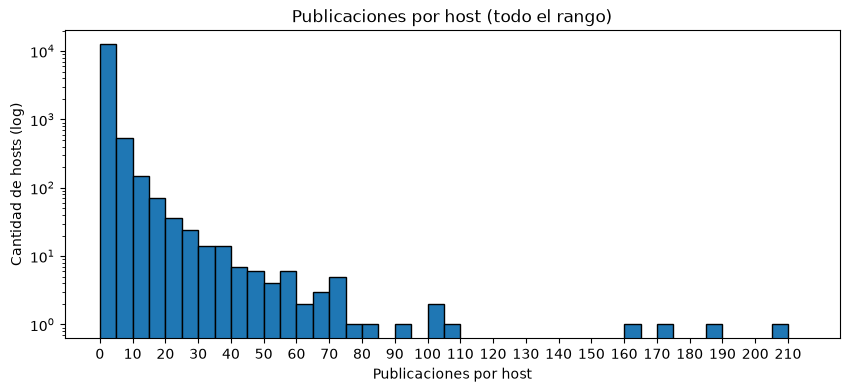

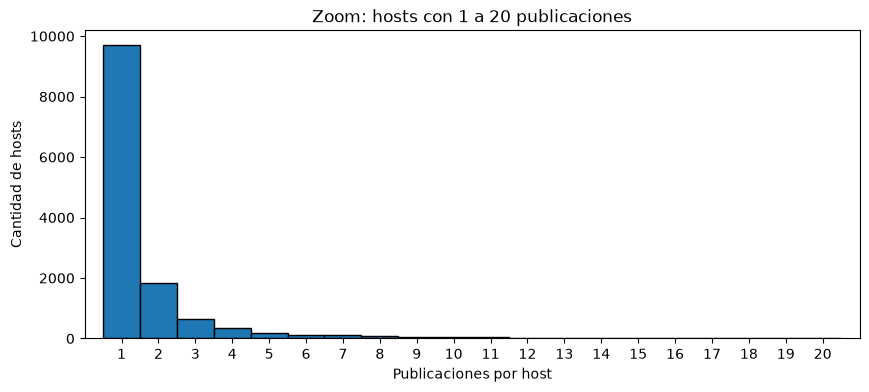

In [36]:
import numpy as np
import matplotlib.pyplot as plt

col = "calculated_host_listings_count"
hosts = preprocessed_dataset.drop_duplicates('host_id')

plt.figure(figsize=(10, 4))
plt.hist(hosts[col], bins=np.arange(0, 220, 5), edgecolor='black')
plt.xticks(np.arange(0, 220, 10))
plt.yscale('log')
plt.xlabel("Publicaciones por host")
plt.ylabel("Cantidad de hosts (log)")
plt.title("Publicaciones por host (todo el rango)")
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(hosts[col], bins=np.arange(0.5, 21.5, 1), edgecolor='black')  # una barra por valor entero
plt.xticks(np.arange(1, 21, 1))
plt.xlim(0, 21)
plt.xlabel("Publicaciones por host")
plt.ylabel("Cantidad de hosts")
plt.title("Zoom: hosts con 1 a 20 publicaciones")
plt.show()


**seccion 1.3**

count    13374.000000
mean         2.122103
std          5.393730
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        208.000000
Name: calculated_host_listings_count, dtype: float64
calculated_host_listings_count
1     9702
2     1826
3      630
4      333
5      192
6      120
7      101
8       67
9       55
10      43
Name: count, dtype: int64


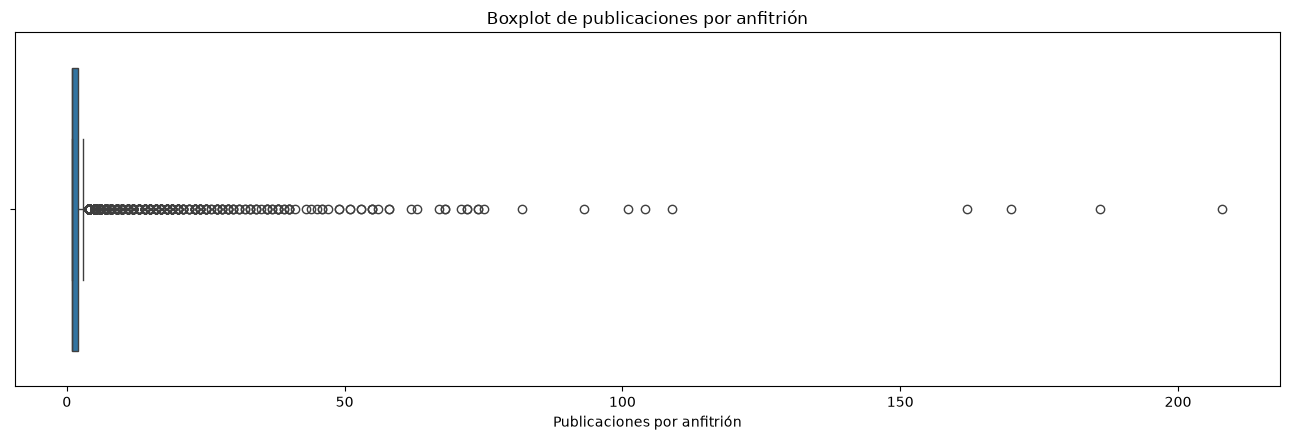

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

c_t = 'calculated_host_listings_count'
hosts = preprocessed_dataset.drop_duplicates('host_id')   # una fila por anfitrión

# Resumen numérico primero
print(hosts[c_t].describe())
print(hosts[c_t].value_counts().sort_index().head(10))

fig, ax = plt.subplots(figsize=(13, 4.5))

sns.boxplot(x=hosts[c_t], ax=ax)
ax.set_title('Boxplot de publicaciones por anfitrión')
ax.set_xlabel('Publicaciones por anfitrión')

plt.tight_layout()
plt.show()

**seccion 1.4**

Por esto, comenzamos filtrando los datos y creando una nueva columna llamada calculated_host_listings_count_entire_homes, y luego filtramos aquellos que tenían dos o más.

In [38]:
import pandas as pd

col = "calculated_host_listings_count_entire_homes"

# Solo alojamientos enteros
ent = preprocessed_dataset[preprocessed_dataset["room_type"] == "Entire home/apt"].copy()

print("Entire home/apt:", len(ent), f"({len(ent)/len(preprocessed_dataset)*100:.1f}%)")

#Filtramos a los que tienen dos o mas propiedades
ent["multi"] = ent[col] >= 2

#Hasta aca creamos una nueva columna que nos permitio identificar a las agencias multipropiedad, en este caso consideramos que tener mas de dos propiedades enteras es multipropiedad

Entire home/apt: 24390 (90.0%)


**seccion 1.5**

Luego, ya teniendo los datos filtrados, quisimos ver cómo se distribuían, para ello hicimos un boxplot.

count    24390.000000
mean        16.030791
std         34.557449
min          1.000000
25%          1.000000
50%          3.000000
75%         13.000000
90%         46.000000
95%         72.000000
99%        186.000000
max        208.000000
Name: calculated_host_listings_count_entire_homes, dtype: float64
Moda: 1
Asimetría: 3.673253723853907


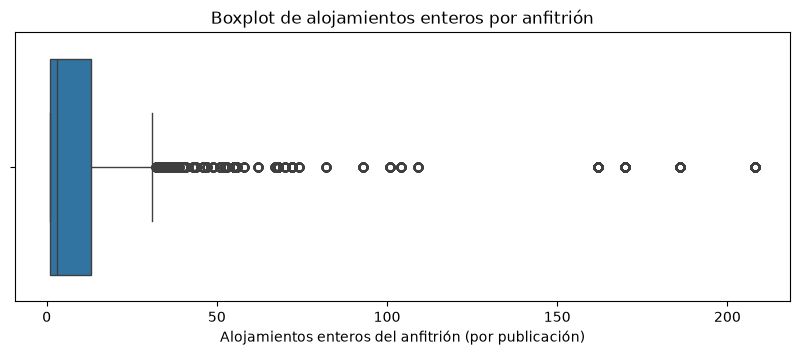

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

col = "calculated_host_listings_count_entire_homes"
v = ent[col]

print(v.describe(percentiles=[.25, .5, .75, .90, .95, .99]))
print("Moda:", v.mode().iloc[0])
print("Asimetría:", v.skew())

plt.figure(figsize=(10, 3.5))
sns.boxplot(x=v)
plt.title("Boxplot de alojamientos enteros por anfitrión")
plt.xlabel("Alojamientos enteros del anfitrión (por publicación)")
plt.show()



Nuestra nueva variable tenía muchos outliers, así que fuimos un poco más allá y analizamos por percentiles. 


**seccion 1.6**

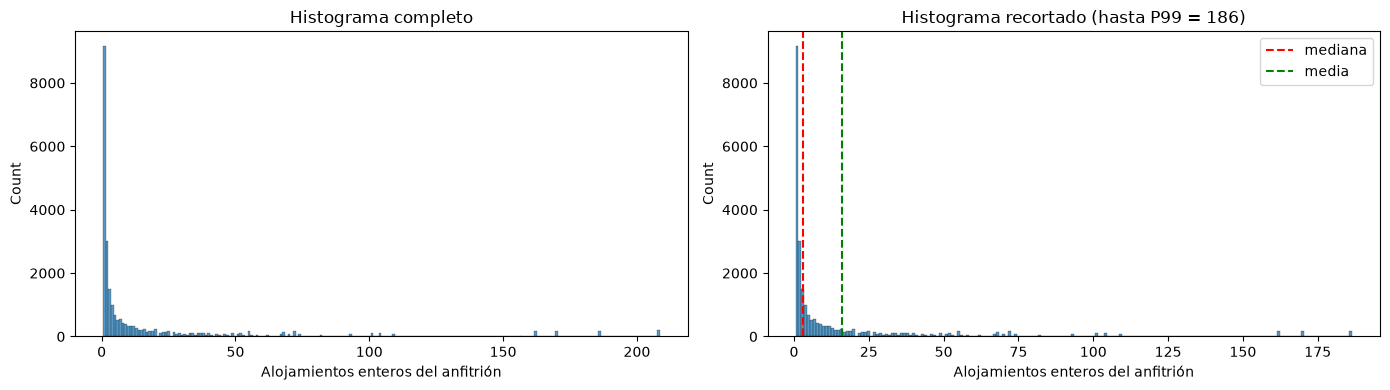

In [40]:

p99 = v.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(v, discrete=True, ax=axes[0])
axes[0].set_title("Histograma completo")
axes[0].set_xlabel("Alojamientos enteros del anfitrión")

sns.histplot(v[v <= p99], discrete=True, ax=axes[1])
axes[1].axvline(v.median(), color="red", linestyle="--", label="mediana")
axes[1].axvline(v.mean(), color="green", linestyle="--", label="media")
axes[1].legend()
axes[1].set_title(f"Histograma recortado (hasta P99 = {p99:.0f})")
axes[1].set_xlabel("Alojamientos enteros del anfitrión")

plt.tight_layout()
plt.show()

Gracias a estos gráficos, más un análisis con el método .describe(), pudimos analizar que el si bien el 50% de los host tenía hasta dos casas o departamentos, había host con más de 200.


**seccion 1.7**

bin
1           37.6
2           12.3
3 a 4       10.2
5 a 9       10.7
10 o más    29.1
Name: proportion, dtype: float64


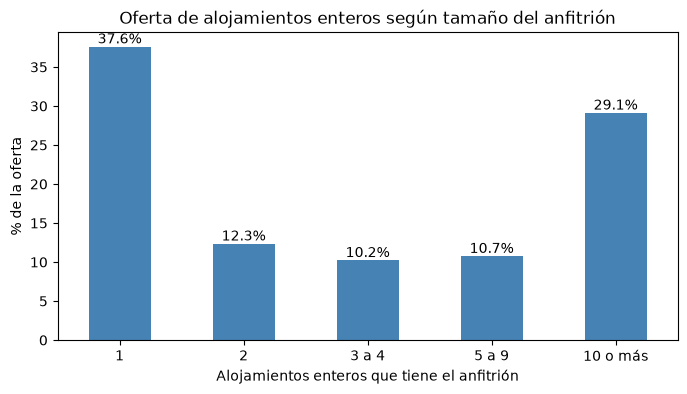

In [41]:
ent["bin"] = pd.cut(
    ent[col],
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=["1", "2", "3 a 4", "5 a 9", "10 o más"]
)

pct = ent["bin"].value_counts(normalize=True).sort_index() * 100
print(pct.round(1))

plt.figure(figsize=(8, 4))
ax = pct.plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.xlabel("Alojamientos enteros que tiene el anfitrión")
plt.ylabel("% de la oferta")
plt.title("Oferta de alojamientos enteros según tamaño del anfitrión")
plt.show()

Este gráfico de barras nos acercó bastante a lo que queríamos saber, la gran mayoría de los huéspedes contaban con 1 sola publicación de casa/departamento entero

### Validacion de la hipotesis

Para validar la hipótesis primero probamos que los datos fueran normales, corriendo un Test de Shapiro, lo cual nos devuelve un p-valor extremadamente chico, por lo que una primera conclusión fue que los datos no seguían una distribución normal. Para poder ver esto visualmente y asegurar el resultado hicimos un QQ-Plot, donde vimos que los datos definitivamente no siguen una distribución normal.

**seccion 1.8**

In [42]:
from scipy.stats import shapiro

col = "calculated_host_listings_count_entire_homes"
muestra = ent[col]

stat, p = shapiro(muestra)
print(f"Shapiro-Wilk ({col}): W={stat:.3f}, p-valor={p:.3g}")

Shapiro-Wilk (calculated_host_listings_count_entire_homes): W=0.480, p-valor=7.12e-123


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 24390.
  res = hypotest_fun_out(*samples, **kwds)


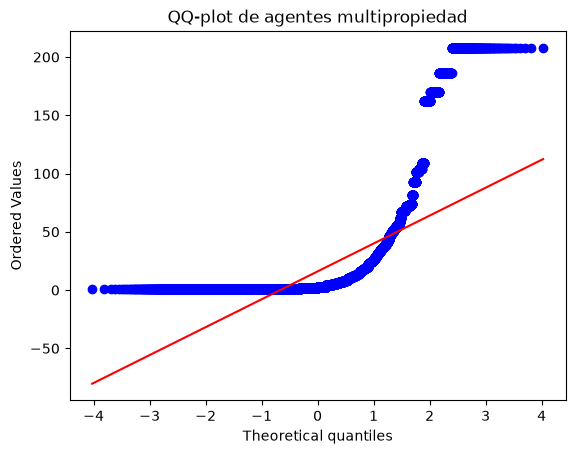

In [43]:
import scipy.stats as st
import matplotlib.pyplot as plt

st.probplot(ent[col], dist="norm", plot=plt)
plt.title("QQ-plot de agentes multipropiedad")
plt.show()

En la validación de esta hipótesis nos encontramos con el problema de que, como los datos no siguen una distribución normal, no podíamos aplicar un Test t para una muestra, por eso hicimos un gráfico para poder ver las proporciones y sacar conclusiones a partir de eso


**seccion 1.9**

Propiedad única             37.6
Multipropiedad (2 o más)    62.4
Name: proportion, dtype: float64


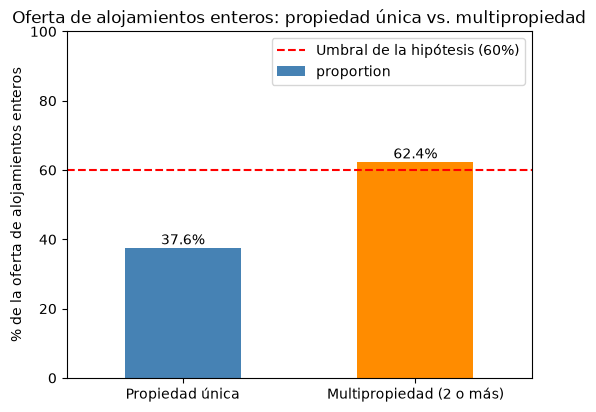

In [44]:
import matplotlib.pyplot as plt

# % de publicaciones según si el anfitrión es multipropiedad
pct = ent["multi"].value_counts(normalize=True).mul(100).reindex([False, True])
pct.index = ["Propiedad única", "Multipropiedad (2 o más)"]

print(pct.round(1))

plt.figure(figsize=(6, 4.5))
ax = pct.plot(kind="bar", color=["steelblue", "darkorange"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.axhline(60, color="red", linestyle="--", label="Umbral de la hipótesis (60%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.ylabel("% de la oferta de alojamientos enteros")
plt.title("Oferta de alojamientos enteros: propiedad única vs. multipropiedad")
plt.legend()
plt.show()

Dada la gráfica podemos concluir que, si consideramos que con tener dos propiedades completas se trata de una agencia multipropiedad, entonces más del 60% son publicaciones de agencias multipropiedad. La diferencia no es mucha, y también depende de que se considere multipropiedad.

## 2 Hipotesis univaridad (grupo):

Los precios de un alquiler para máximo 2 personas, por noche, en la ciudad de Buenos Aires  supera los 100.000 pesos.

### Analisis exploratorio:

**seccion 2.1**

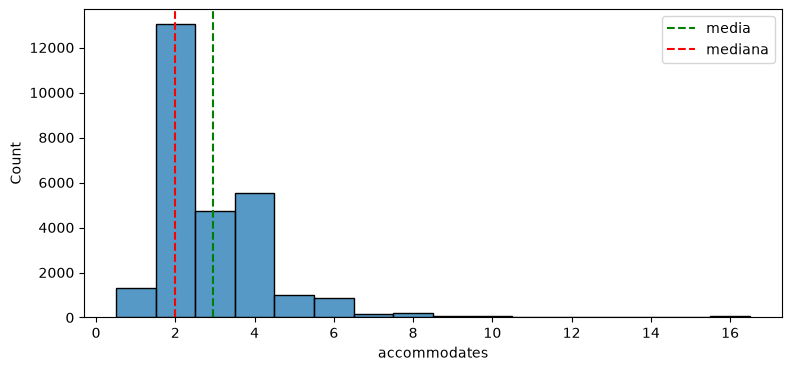

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
acc = preprocessed_dataset["accommodates"].dropna()

plt.figure(figsize=(9, 4))
sns.histplot(acc, discrete=True)
plt.axvline(acc.mean(), color="green", linestyle="--", label="media")
plt.axvline(acc.median(), color="red", linestyle="--", label="mediana")
plt.legend()
plt.show()

**seccion 2.2**

Nulos: 0
Categorías: 4
Moda: Entire home/apt
                 Frecuencia  Porcentaje
room_type                              
Entire home/apt       24390       89.99
Private room           2455        9.06
Shared room             132        0.49
Hotel room              125        0.46


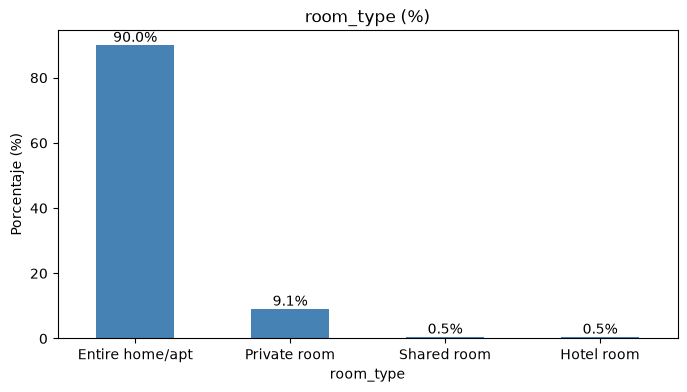

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rt = preprocessed_dataset["room_type"]

print("Nulos:", rt.isna().sum())
print("Categorías:", rt.nunique())
print("Moda:", rt.mode().iloc[0])

frec = rt.value_counts()
prop = rt.value_counts(normalize=True) * 100

tabla = pd.DataFrame({"Frecuencia": frec, "Porcentaje": prop.round(2)})
print(tabla)

orden = rt.value_counts().index
plt.figure(figsize=(8, 4))
ax = prop.plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.title("room_type (%)")
plt.show()

**seccion 2.3**

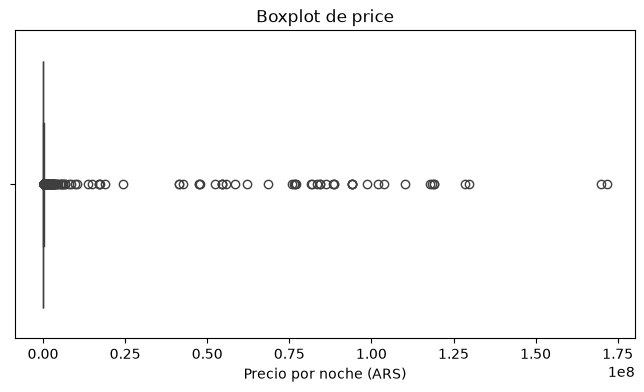

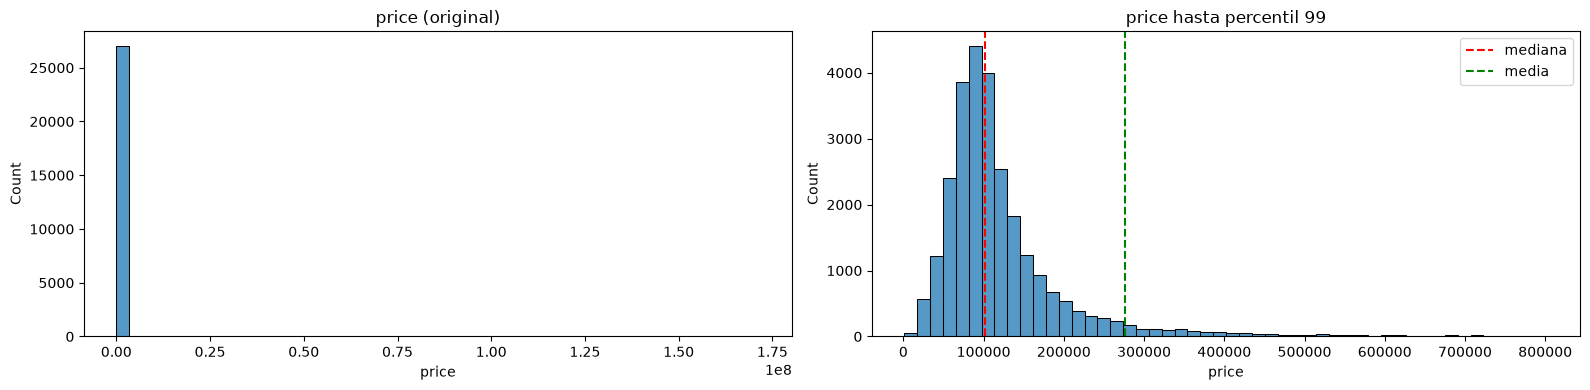

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(x=preprocessed_dataset["price"])
plt.title("Boxplot de price")
plt.xlabel("Precio por noche (ARS)")
plt.show()

precio = preprocessed_dataset["price"]

fig, ax = plt.subplots(1, 2, figsize=(16, 4))

# a) Original
sns.histplot(precio, bins=50, ax=ax[0])
ax[0].set_title("price (original)")

# b) Recortado al percentil 99
p99 = precio.quantile(0.99)
sns.histplot(precio[precio <= p99], bins=50, ax=ax[1])
ax[1].axvline(precio.median(), color="red", linestyle="--", label="mediana")
ax[1].axvline(precio.mean(), color="green", linestyle="--", label="media")
ax[1].legend()
ax[1].set_title("price hasta percentil 99")

plt.tight_layout()
plt.show()
#En el siguiente boxpot podemos ver que es un varibale con una gran cantidad de outliers, entonces vamos a intentar filtrar nuestros datos para que el analisis tenga mas valor,
#obviamente comparar el precio de una habitacion compartida con una mansion no tiene mucho sentido, apunta a gente diferente

Nuestro analisis lo vamos a hacer sobre alojamientos de hasta dos personas, ya que la gran mayoria ofrece para esa cantidad y creemos que es un buen analisis

**seccion 2.5**

n: 14349
count    1.434900e+04
mean     2.576294e+05
std      3.854209e+06
min      1.215500e+03
1%       2.225014e+04
5%       3.549000e+04
25%      6.558767e+04
50%      8.650700e+04
75%      1.113359e+05
90%      1.508543e+05
95%      1.955337e+05
99%      5.020737e+05
max      1.716438e+08
Name: price, dtype: float64


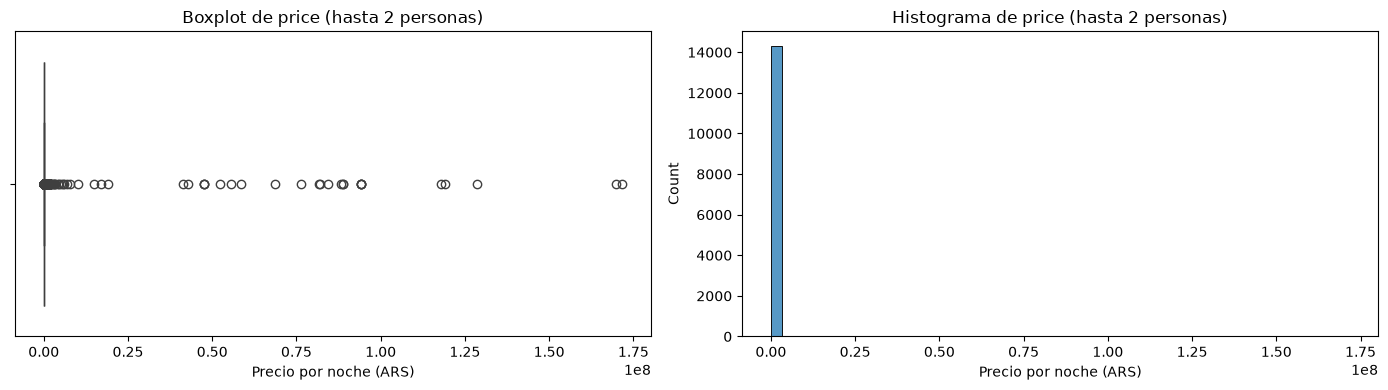

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
grupo = preprocessed_dataset[preprocessed_dataset["accommodates"] <= 2].copy()
precio = grupo["price"]

print("n:", len(grupo))
print(precio.describe(percentiles=[.01, .05, .25, .5, .75, .90, .95, .99]))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=precio, ax=ax[0])
ax[0].set_title("Boxplot de price (hasta 2 personas)")
ax[0].set_xlabel("Precio por noche (ARS)")

sns.histplot(precio, bins=50, ax=ax[1])
ax[1].set_title("Histograma de price (hasta 2 personas)")
ax[1].set_xlabel("Precio por noche (ARS)")

plt.tight_layout()
plt.show()
#podemos ver que seguimos teniendo outliers

**seccion 2.6**

In [50]:
#Limpiamos outliers, nos quedamos con las muestras que se distribuyen dentro los bigotes del boxplot
#Estamos quedandonos con los datos que se distribuyen dentro de los bigotes, de esta manera evitamos outliers, que vemos que representan el 6.24%, esta decision la tomamos xq queremos compara comparar
# alojamientos dentro del mismo rango de precios, entonces consideramos que tener en cuenta los datos que se distribuyen dentro del box plot con 4 cuartiles es una buena forma
precio = grupo["price"]

q1 = precio.quantile(0.25)
q3 = precio.quantile(0.75)
iqr = q3 - q1

lim_sup = q3 + 1.5 * iqr

grupo_limpio = grupo[grupo["price"] <= lim_sup].copy()

print("Límite superior (Q3 + 1,5·IQR):", lim_sup)
print("Bigote máximo (mayor precio que queda):", grupo_limpio["price"].max())
print("Registros antes:", len(grupo))
print("Registros después:", len(grupo_limpio))
print("Eliminados:", len(grupo) - len(grupo_limpio),
      f"({(1 - len(grupo_limpio) / len(grupo)) * 100:.2f}%)")

Límite superior (Q3 + 1,5·IQR): 179958.345
Bigote máximo (mayor precio que queda): 179908.0
Registros antes: 14349
Registros después: 13469
Eliminados: 880 (6.13%)


**seccion 2.7**

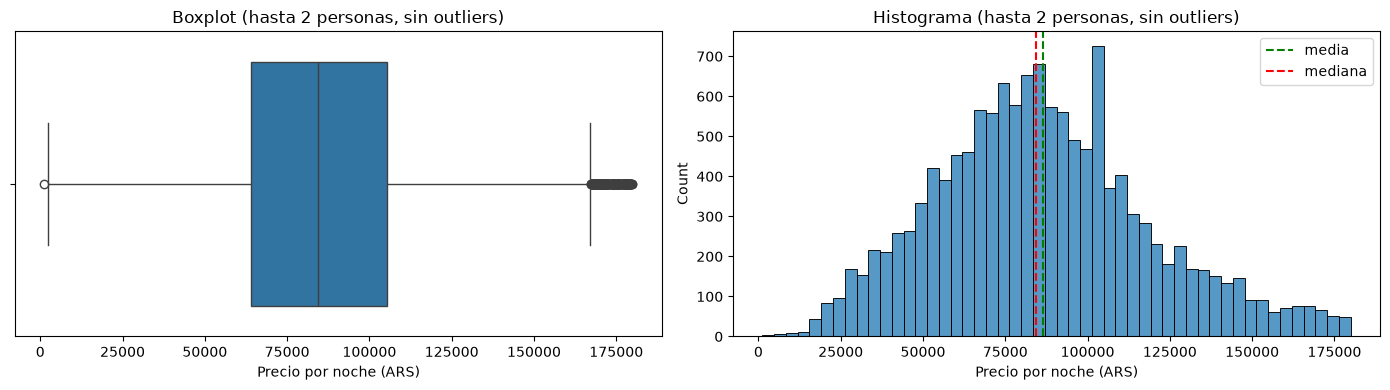

count     13469.000000
mean      86426.109548
std       32664.677861
min        1215.500000
1%        21958.656000
5%        34501.312000
25%       63995.640000
50%       84378.000000
75%      105295.330000
95%      146302.200000
99%      170783.920000
max      179908.000000
Name: price, dtype: float64


In [51]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=grupo_limpio["price"], ax=ax[0])
ax[0].set_title("Boxplot (hasta 2 personas, sin outliers)")
ax[0].set_xlabel("Precio por noche (ARS)")

sns.histplot(grupo_limpio["price"], bins=50, ax=ax[1])
ax[1].axvline(grupo_limpio["price"].mean(), color="green", linestyle="--", label="media")
ax[1].axvline(grupo_limpio["price"].median(), color="red", linestyle="--", label="mediana")
ax[1].legend()
ax[1].set_title("Histograma (hasta 2 personas, sin outliers)")
ax[1].set_xlabel("Precio por noche (ARS)")

plt.tight_layout()
plt.show()

print(grupo_limpio["price"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

**seccion 2.8**

In [52]:
# Test de Shapiro-Wilk para price
from scipy.stats import shapiro

precio= grupo_limpio["price"]
stat, p = shapiro(precio)
print(f"Test de Shapiro-Wilk, precio de alquileres por noche: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk, precio de alquileres por noche: Estadístico=0.988, p-valor=0.000


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 13469.
  res = hypotest_fun_out(*samples, **kwds)


**seccion 2.9**

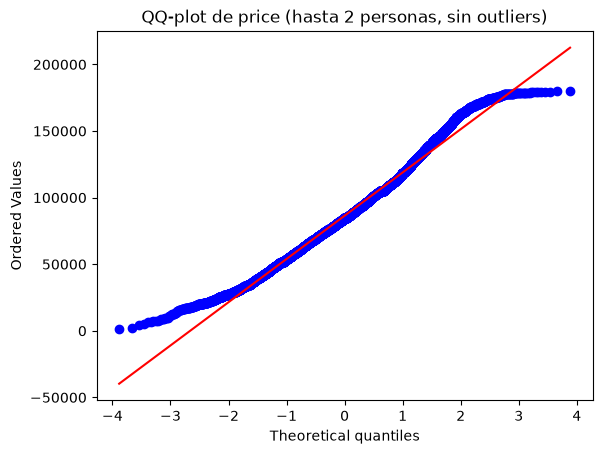

In [53]:
import scipy.stats as st
import matplotlib.pyplot as plt

st.probplot(grupo_limpio["price"], dist="norm", plot=plt)
plt.title("QQ-plot de price (hasta 2 personas, sin outliers)")
plt.show()


## 3 Hipotesis bivariada (catedra):

Alquilar un espacio entero cuesta, en promedio, más del doble que alquilar una habitación privada.

### Analisis exploratorio

**seccion 3.1**

In [72]:
preprocessed_dataset['room_type'].value_counts()

room_type
Entire home/apt    26396
Private room        2471
Hotel room           139
Shared room           85
Name: count, dtype: int64

**seccion 3.2**

Al analizar la variable ``type_room`` vemos que hay cuatro tipos de alquileres: casa completa, habitación privada, habitación de hotel, y habitación compartida. Al ver la metadata podemos analizar que una habitación de hotel puede ser privada o compartida, así que no tendremos en cuenta estas filas en nuestro análisis.

Usaremos private_room y shared_room para hacer una columna derivada is_private (cualitativa dicotómica) que luego analizaremos en contra de los precios.

In [73]:
import numpy as np

# Si room_type es 'Private room', asigna 1; en caso contrario (ej. 'Entire home/apt', etc.), asigna 0
preprocessed_dataset['is_private'] = np.where(preprocessed_dataset['room_type'] == 'Private room', 1, 0)
preprocessed_dataset['is_private'].value_counts()

is_private
0    26620
1     2471
Name: count, dtype: int64

BORRADO DE NULOS EN is_private

**seccion 3.3**

In [74]:
preprocessed_dataset = preprocessed_dataset.dropna(subset=['is_private'])
preprocessed_dataset.info()


<class 'pandas.DataFrame'>
Index: 29091 entries, 0 to 29684
Data columns (total 67 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29091 non-null  int64  
 1   last_scraped                                  29091 non-null  str    
 2   source                                        29091 non-null  bool   
 3   name                                          29091 non-null  str    
 4   description                                   28334 non-null  str    
 5   hosts_time_as_user_years                      29091 non-null  int64  
 6   hosts_time_as_user_months                     29091 non-null  int64  
 7   hosts_time_as_host_years                      29091 non-null  int64  
 8   hosts_time_as_host_months                     29091 non-null  int64  
 9   host_location                                 22643 non-null  str    
 10  ho

**seccion 3.4**

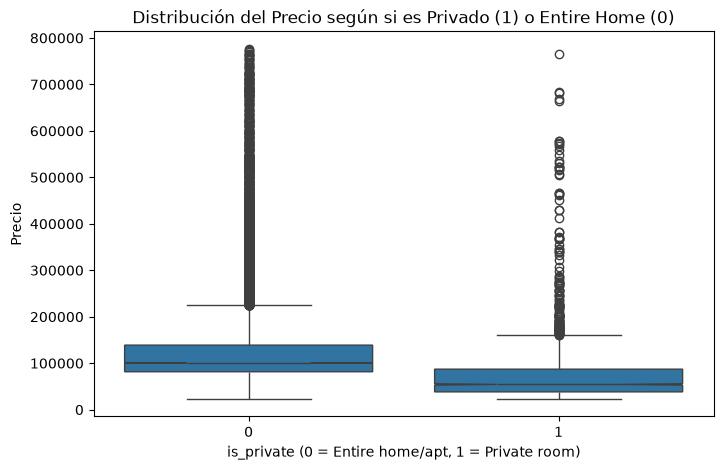

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x='is_private', y='price', data=preprocessed_dataset, notch = True)
plt.title('Distribución del Precio según si es Privado (1) o Entire Home (0)')
plt.xlabel('is_private (0 = Entire home/apt, 1 = Private room)')
plt.ylabel('Precio')
plt.show()



### Validacion de hipotesis:

NORMALIDAD: SHAPIRO

**seccion 3.5**

In [76]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
private = preprocessed_dataset[preprocessed_dataset['is_private'] == 1]['price']
entire_home = preprocessed_dataset[preprocessed_dataset['is_private'] == 0]['price']

# Test de Shapiro-Wilk para habitaciones privadas
stat, p = shapiro(private)
print(f"Test de Shapiro-Wilk habitaciones privadas: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Shapiro-Wilk para alojamientos enteros
stat, p = shapiro(entire_home)
print(f"Test de Shapiro-Wilk para alojamientos enteros: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk habitaciones privadas: Estadístico=0.573, p-valor=0.000
Test de Shapiro-Wilk para alojamientos enteros: Estadístico=0.690, p-valor=0.000


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 26620.
  res = hypotest_fun_out(*samples, **kwds)


NORMALIDAD KOLMOGOROV

**seccion3.6**

In [ ]:
from scipy.stats import kstest

# Test de Kolmogorov-Smirnov para habitaciones privadas
stat, p = kstest(private, 'norm')
print(f"Test de Kolmogorov-Smirnov para habitaciones privadas: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Kolmogorov-Smirnov para alojamientos enteros
stat, p = kstest(entire_home, 'norm')
print(f"Test de Kolmogorov-Smirnov para alojamientos enteros: Estadístico={stat:.3f}, p-valor={p:.3f}")

QQ PLOT precio con is_private

**seccion 3.7**

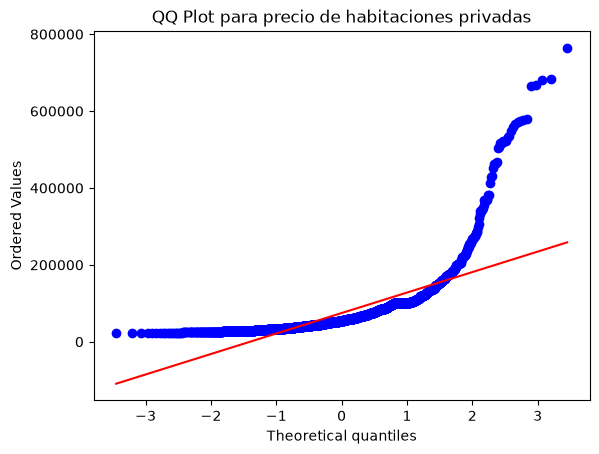

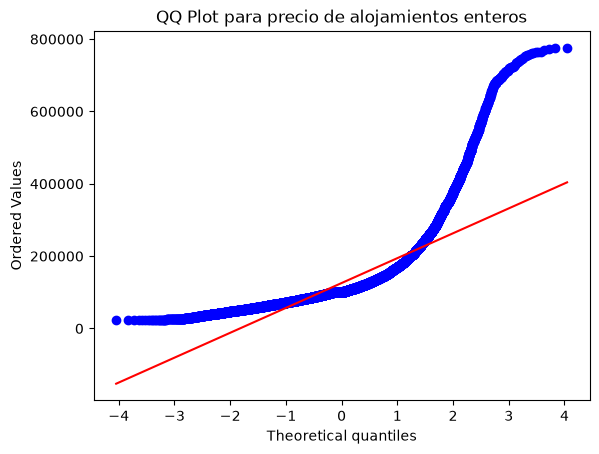

In [ ]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# QQ plot habitaciones privadas
stats.probplot(private, dist="norm", plot=plt)
plt.title("QQ Plot para precio de habitaciones privadas")
plt.show()

# QQ plot alojamientos enteros
stats.probplot(entire_home, dist="norm", plot=plt)
plt.title("QQ Plot para precio de alojamientos enteros")
plt.show()

**seccion 3.8**

LEVENE precio E is_private

In [ ]:
stat, p = stats.levene(private, entire_home)
print(f"Test de Levene para precio: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para precio: Estadístico=46.802, p-valor=0.000


KRUSKAL precio E is_private

In [ ]:
# Test de Kruskal-Wallis para comparar precio entre habitaciones privadas y alojamientos completos
stat, p = stats.kruskal(entire_home, private)
print(f"Test de Kruskal-Wallis para precio: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en el precio entre habitaciones privadas y alojamientos enteros.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en el precio entre habitaciones privadas y alojamientos enteros.")

Test de Kruskal-Wallis para precio: Estadístico=2433.801, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en el precio entre habitaciones privadas y alojamientos enteros.


## 4 Hipotesis bivariada (grupo):

-Ser superhost suele subir la cantidad de días de ocupación estimada en un año

Variables: host_is_superhost y availability_365 

BOXPLOT DE DISTRIBUCIÓN DE LA OCUPACIÓN EN EL ULTIMO AÑO CON SUPERHOST

**seccion 4.1**

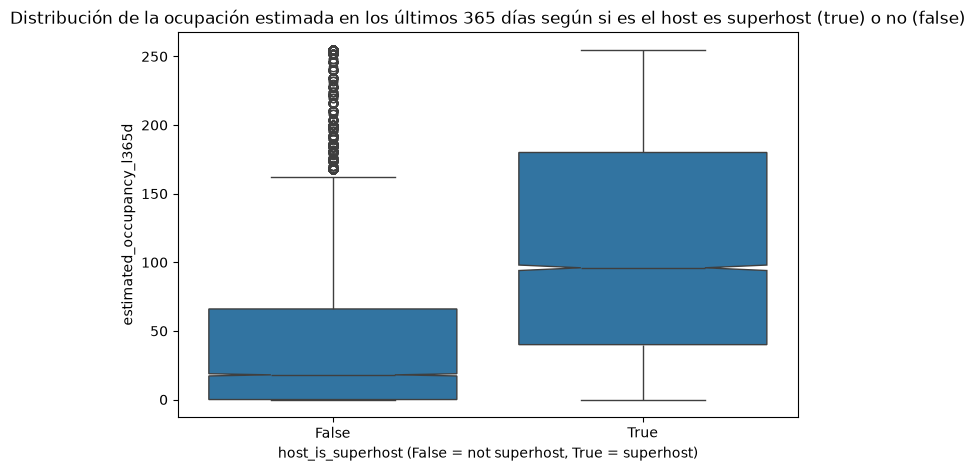

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x='host_is_superhost', y='estimated_occupancy_l365d', data=preprocessed_dataset, notch= True)
plt.title('Distribución de la ocupación estimada en los últimos 365 días según si es el host es superhost (true) o no (false)')
plt.xlabel('host_is_superhost (False = not superhost, True = superhost)')
plt.ylabel('estimated_occupancy_l365d')
plt.show()


KOLMOGOROV 

**seccion 4.2**

In [ ]:
from scipy.stats import kstest

# 1. Filtrar la ocupación para los que SÍ son superhost
occupancy_superhost = preprocessed_dataset[preprocessed_dataset['host_is_superhost'] == True]['estimated_occupancy_l365d']

# 2. Filtrar la ocupación para los que NO son superhost
occupancy_nosuperhost = preprocessed_dataset[preprocessed_dataset['host_is_superhost'] == False]['estimated_occupancy_l365d']

# Test de Kolmogorov-Smirnov para Superhost
stat_s, p_s = kstest(occupancy_superhost, 'norm')
print(f"Test de Kolmogorov-Smirnov (occupancy_superhost): Estadístico={stat_s:.3f}, p-valor={p_s:.3f}")

# Test de Kolmogorov-Smirnov para No Superhost
stat_ns, p_ns = kstest(occupancy_nosuperhost, 'norm')
print(f"Test de Kolmogorov-Smirnov (occupancy_nosuperhost): Estadístico={stat_ns:.3f}, p-valor={p_ns:.3f}")

Test de Kolmogorov-Smirnov (occupancy_superhost): Estadístico=0.928, p-valor=0.000
Test de Kolmogorov-Smirnov (occupancy_nosuperhost): Estadístico=0.653, p-valor=0.000


LEVENE OCUPACION SUPERHOST Y NO SUPERHOST

In [ ]:
stat, p = stats.levene(occupancy_superhost, occupancy_nosuperhost)
print(f"Test de Levene para la ocupación del alojamiento en el último año: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para la ocupación del alojamiento en el último año: Estadístico=1450.084, p-valor=0.000


QQ PLOT SUPERHOST Y NO SUPERHOST CON OCUPACION

**seccion 4.4**

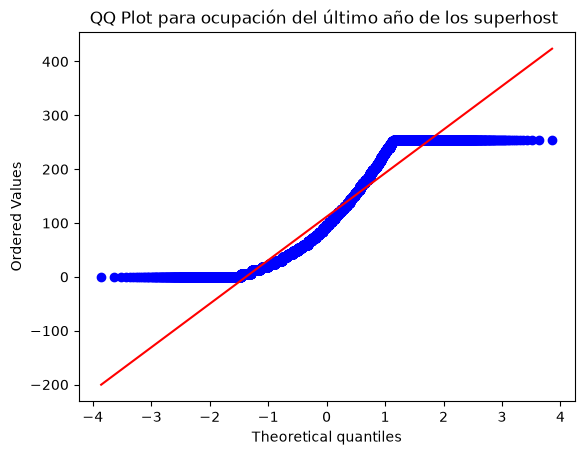

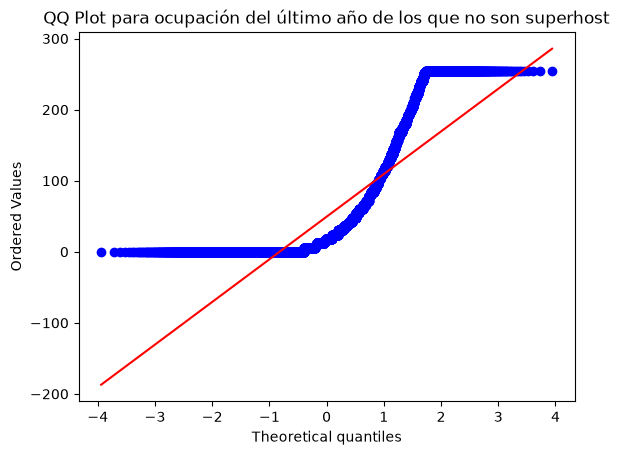

In [ ]:
import matplotlib.pyplot as plt
import scipy.stats as stats

stats.probplot(occupancy_superhost, dist="norm", plot=plt)
plt.title("QQ Plot para ocupación del último año de los superhost ")
plt.show()

stats.probplot(occupancy_nosuperhost, dist="norm", plot=plt)
plt.title("QQ Plot para ocupación del último año de los que no son superhost")
plt.show()


KRUSKAL

**seccion 4.5**

In [ ]:
# Test de Kruskal-Wallis para comparar disponibilidad a 365 dias para superhosts y no superhosts
stat, p = stats.kruskal(occupancy_superhost, occupancy_nosuperhost)
print(f"Test de Kruskal-Wallis para ocupación en los últimos 365 días: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la ocupación de superhosts y no superhosts.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la ocupación de superhosts y no superhosts")

Test de Kruskal-Wallis para ocupación en los últimos 365 días: Estadístico=5144.471, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la ocupación de superhosts y no superhosts


## 5 Hipotesis multivariada (grupo):

### Preprocesamiento de las varaibles

**Preprocesamiento de las variables del análisis**

Para esta hipotesis estan involucradas las variables ``room_type``, ``estimated_occupancy_l365d``, ``estimated_revenue_l365d`` y ``neighbourhood_cleansed``. 

Dentro del analisis encontramos que `estimated_revenue_l365d` tiene 1.797 filas nulas y 6.346 filas donde es igual a 0 (concuerda con que no haya ocupacion en esos alojamientos), Son alojamientos sin noches ocupadas estimadas en el último año, por lo que no aportan información para comparar ingresos entre barrios. Además, concentran una masa de valores en 0 que distorsiona la distribución y la varianza (quedaron 21.542 filas).

**seccion 5.1**

In [ ]:
cols = ["room_type", "estimated_occupancy_l365d",
        "estimated_revenue_l365d", "neighbourhood_cleansed"]
df_multi = preprocessed_dataset[cols].dropna().copy()
df_multi = df_multi[df_multi["estimated_revenue_l365d"] > 0].copy()
print(df_multi.shape)  # (27888, 4)

(20721, 4)


Para el trato de los outliers se eliminaron los valores de ingreso por encima de Q3 + 1,5·IQR. No hay outliers por debajo, porque la cerca inferior es negativa. Los valores extremos influyen mucho en las medias y las varianzas, y dominan la comparación entre grupos. Además, casi todos los outliers corresponden a departamentos enteros, por lo que no se pierde información de las categorías con poca muestra.

**seccion 5.2**

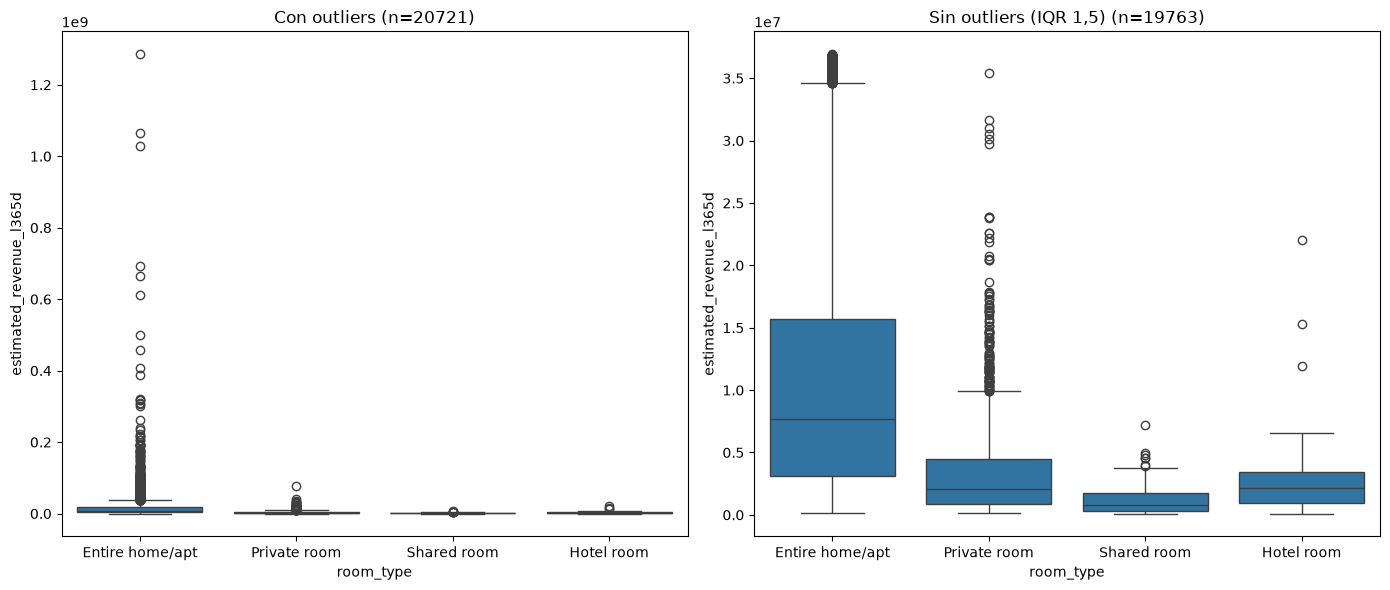

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

q1, q3 = df_multi["estimated_revenue_l365d"].quantile([0.25, 0.75])
limite_sup = q3 + 1.5 * (q3 - q1)
df_sin_out = df_multi[df_multi["estimated_revenue_l365d"] <= limite_sup]

orden = ["Entire home/apt", "Private room", "Shared room", "Hotel room"]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, data, t in [(ax[0], df_multi, "Con outliers"),
                   (ax[1], df_sin_out, "Sin outliers (IQR 1,5)")]:
    sns.boxplot(data=data, x="room_type", y="estimated_revenue_l365d",
                order=orden, ax=a)
    a.set_title(f"{t} (n={len(data)})")
plt.tight_layout()
plt.show()

In [ ]:
q1, q3 = df_multi["estimated_revenue_l365d"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr

df_multi = df_multi[df_multi["estimated_revenue_l365d"] <= limite_sup].copy()
print("Cantidad de filas restantes luego de eliminar los outliers:", df_multi.shape)  # (20534, 4)

Cantidad de filas restantes luego de eliminar los outliers: (19763, 4)


Realizamos gráficos boxplots para ver cómo se comportan las variables con respecto a el precio estimado

**seccion 5.3**

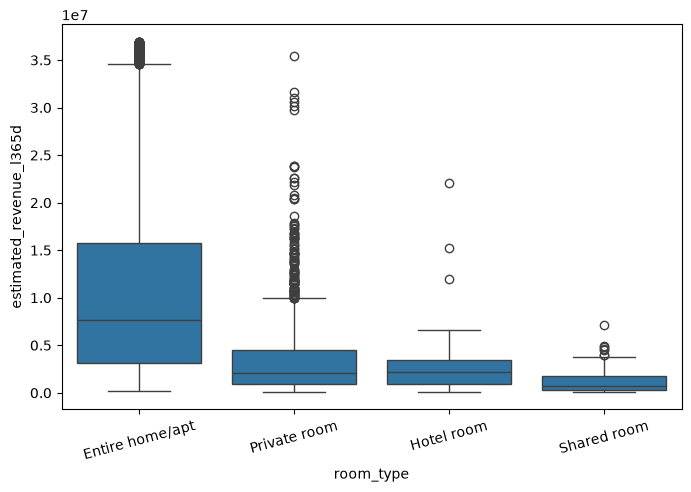

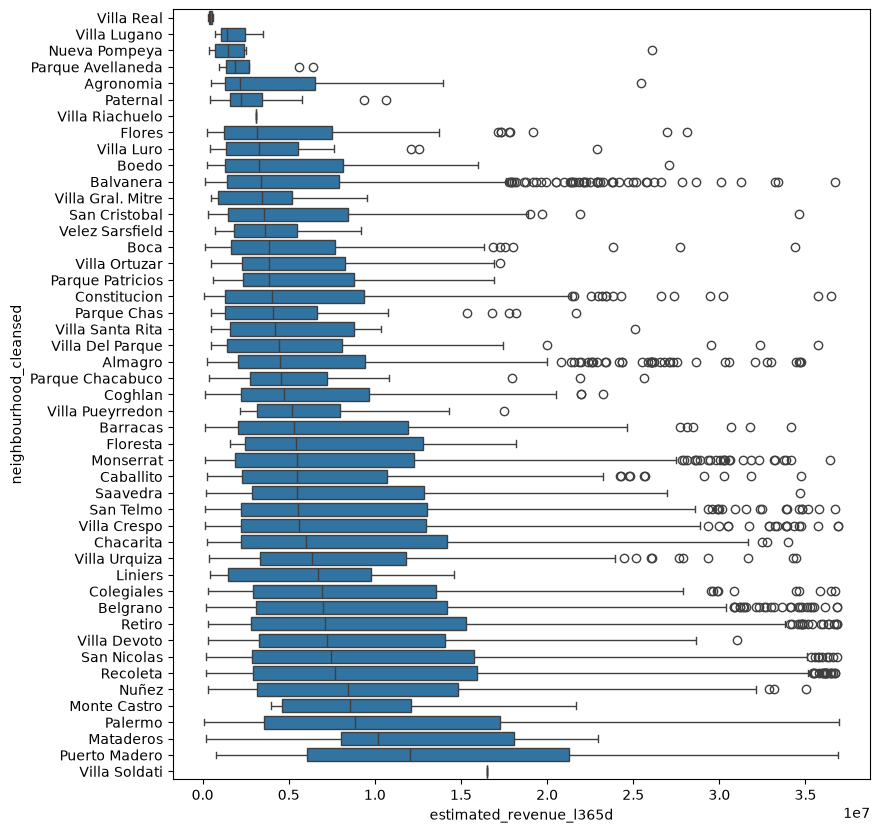

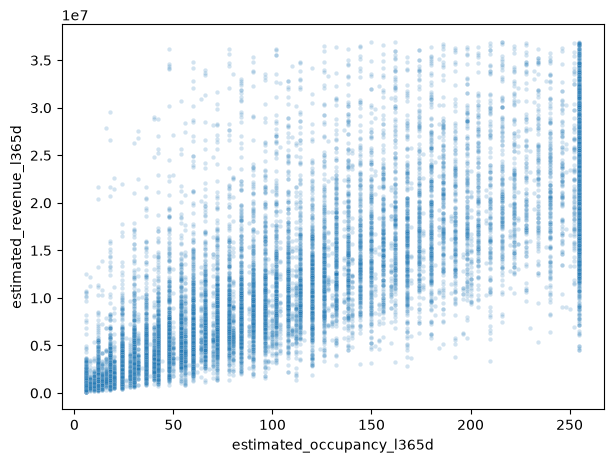

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. log(ingreso) por tipo de habitación
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_multi, x='room_type', y='estimated_revenue_l365d')
plt.xticks(rotation=15)
plt.show()

# 2. log(ingreso) por barrio, ordenado por mediana
orden = df_multi.groupby('neighbourhood_cleansed')['estimated_revenue_l365d'].median().sort_values().index
plt.figure(figsize=(9, 10))
sns.boxplot(data=df_multi, y='neighbourhood_cleansed', x='estimated_revenue_l365d', order=orden)
plt.show()

# 3. log(ingreso) contra log(ocupación)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_multi, x='estimated_occupancy_l365d', y='estimated_revenue_l365d', alpha=0.2, s=10)
plt.show()

In [ ]:
tabla = pd.crosstab(df_multi['neighbourhood_cleansed'], df_multi['room_type'])
tabla['Total'] = tabla.sum(axis=1)
tabla = tabla.sort_values('Total', ascending=False)
tabla.loc['Total'] = tabla.sum()

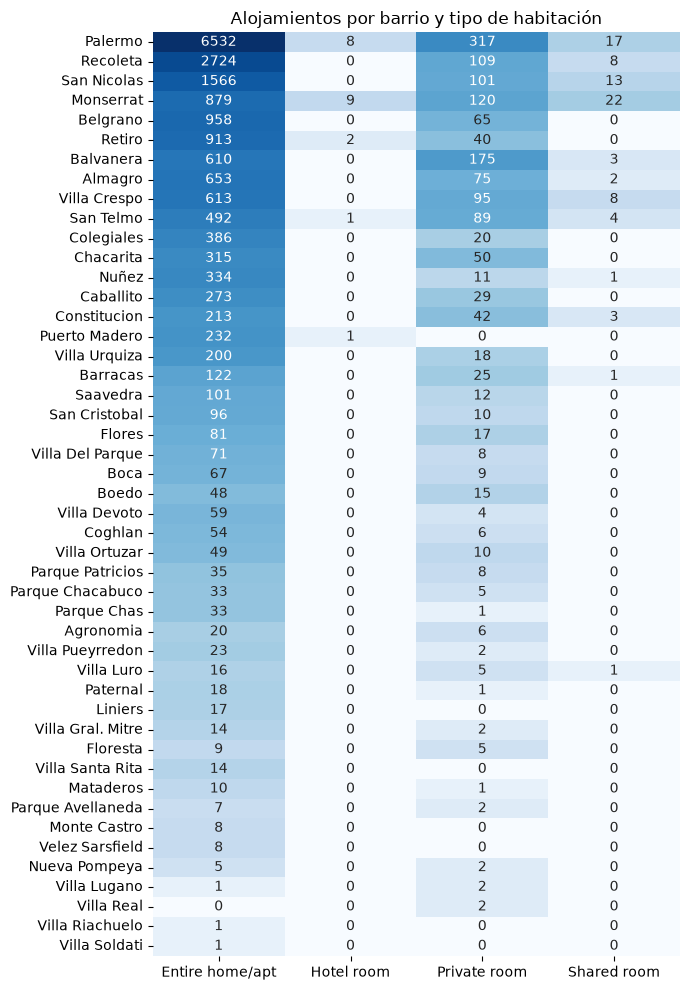

In [ ]:
import numpy as np

datos = tabla.drop(index='Total', columns='Total')

plt.figure(figsize=(7, 10))
sns.heatmap(np.log1p(datos), annot=datos, fmt='d', cmap='Blues', cbar=False)
plt.title('Alojamientos por barrio y tipo de habitación')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.savefig('tabla_cruzada.png', dpi=200)
plt.show()

En el boxplot de ingreso por barrio, los barrios con muy pocas observaciones muestran cajas degeneradas: Villa Real, Villa Riachuelo y Villa Soldati aparecen como un punto o una línea (entre 1 y 2 alojamientos), y Villa Lugano, Nueva Pompeya o Parque Avellaneda tienen cajas muy angostas (entre 3 y 9). Con tan pocos datos, la mediana y los cuartiles dependen de uno o dos alojamientos y no representan al barrio. La tabla cruzada barrio x tipo de habitación confirma que esos barrios tienen casi todas las celdas vacías o con muy pocos casos.

decidimos tomar 30 observaciones como mínimo por barrio. Por debajo, las diferencias entre barrios podrían deberse al azar de la muestra y no a un efecto real. Se descartó agrupar estos barrios en una categoría "Otros" porque mezclaría barrios muy distintos y no tendría una interpretación geográfica.

In [ ]:
conteo = df_multi["neighbourhood_cleansed"].value_counts()
barrios_validos = conteo[conteo >= 30].index
df_multi = df_multi[df_multi["neighbourhood_cleansed"].isin(barrios_validos)].copy()
print(df_multi.shape, df_multi["neighbourhood_cleansed"].nunique())  # (20331, 4) 30

(19568, 4) 30


Vemos como no perdemos tantas filas si eliminamos del analisis a los barrios que no llegan a los 30 alojamientos.

Ahora miremos como se comportan los datos luego del recorte que realizamos

**seccion 5.4**

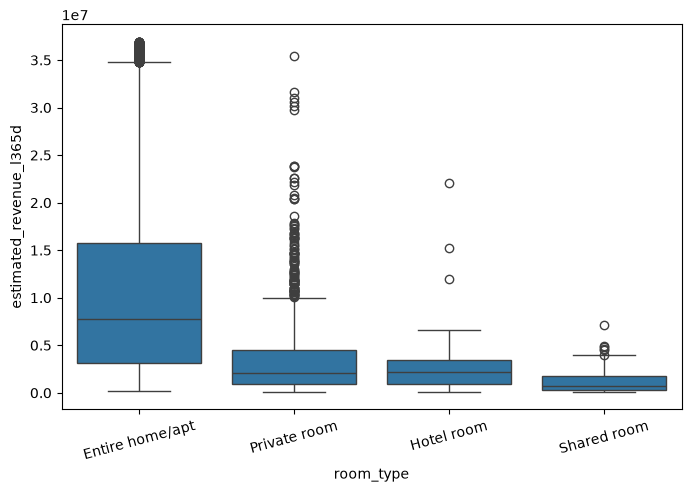

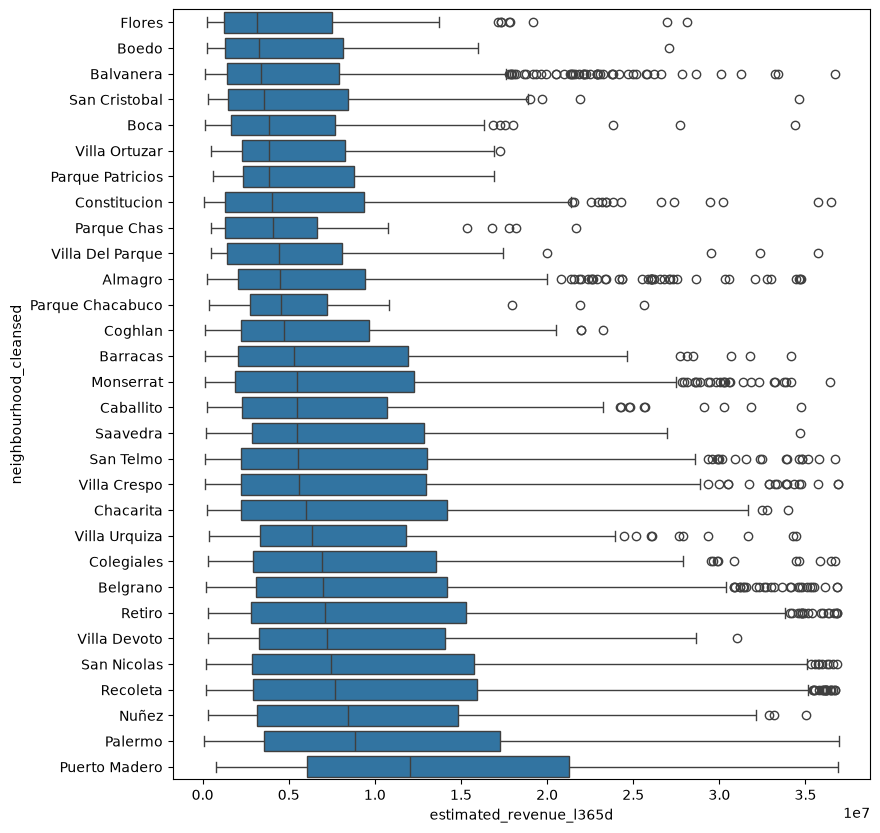

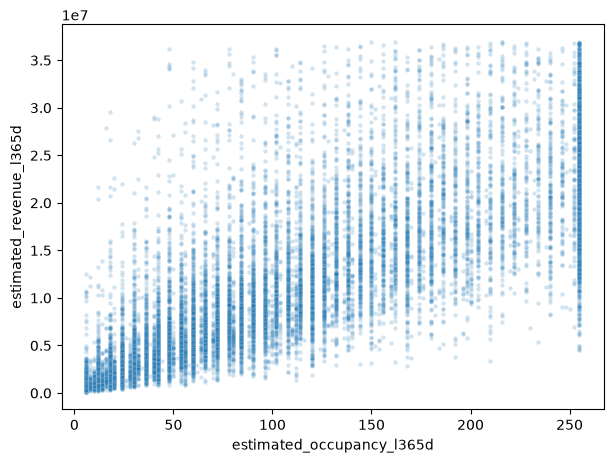

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. log(ingreso) por tipo de habitación
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_multi, x='room_type', y='estimated_revenue_l365d')
plt.xticks(rotation=15)
plt.show()

# 2. log(ingreso) por barrio, ordenado por mediana
orden = df_multi.groupby('neighbourhood_cleansed')['estimated_revenue_l365d'].median().sort_values().index
plt.figure(figsize=(9, 10))
sns.boxplot(data=df_multi, y='neighbourhood_cleansed', x='estimated_revenue_l365d', order=orden)
plt.show()

# 3. log(ingreso) contra log(ocupación)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_multi, x='estimated_occupancy_l365d', y='estimated_revenue_l365d', alpha=0.2, s=10)
plt.show()

**Observaciones del análisis exploratorio**

- _Ingreso por barrio_: las medianas y la dispersión del ingreso cambian de un barrio a otro, lo que sugiere que el barrio influye en el ingreso de un host.
- _Ingreso por tipo de habitación_: las cajas se ordenan de forma coherente con lo que ofrece cada categoría: los departamentos enteros tienen los mayores ingresos y las habitaciones compartidas los menores.
- _Ingreso vs ocupación_: la nube sube de forma aproximadamente lineal con la ocupación, por lo que es necesario controlar por esta variable. Además, la dispersión del ingreso crece al aumentar la ocupación (forma de abanico), lo que anticipa heterocedasticidad, y hay una columna vertical en 255 noches, que es el tope de la variable.

### Validacion de hipotesis:

H0: a igual ocupación y room_type, el ingreso anual estimado no difiere entre barrios.

H1: al menos un barrio difiere.

**Modelo OLS**

Se ajusta un OLS con ingreso ~ ocupación + room_type + barrio. Las categorías de referencia son Entire home/apt y Almagro, así que cada coeficiente es una diferencia respecto de ellas.

**seccion 5.5**

In [ ]:
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
import matplotlib.pyplot as plt

modelo = smf.ols(
    "estimated_revenue_l365d ~ estimated_occupancy_l365d + C(room_type) + C(neighbourhood_cleansed)",
    data=df_multi).fit()
print(modelo.summary())

                               OLS Regression Results                              
Dep. Variable:     estimated_revenue_l365d   R-squared:                       0.710
Model:                                 OLS   Adj. R-squared:                  0.709
Method:                      Least Squares   F-statistic:                     1449.
Date:                     Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                             21:24:20   Log-Likelihood:            -3.2811e+05
No. Observations:                    19568   AIC:                         6.563e+05
Df Residuals:                        19534   BIC:                         6.566e+05
Df Model:                               33                                         
Covariance Type:                 nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------

**Conclusiones que podemos sacar del modelo de regresion**


- El modelo explica el 70,2 % de la variación del ingreso (R² = 0,702).
- _Ocupación_: cada noche adicional se asocia con unos 86.320 de ingreso anual más, a igual room_type y barrio (t = 206).
- _room_type_: la habitación privada rinde unos 3,45 M menos que el departamento entero y la compartida unos 4,82 M menos, ambas significativas. La de hotel muestra una diferencia de −1,53 M que no es significativa (p = 0,135), algo esperable con solo 21 observaciones.
- _Barrio_: 14 de los 29 coeficientes son significativos respecto de Almagro. Los mayores son Puerto Madero (+6,52 M), Palermo (+2,13 M), Recoleta (+2,02 M), Colegiales (+2,01 M) y Belgrano (+1,78 M). Parque Patricios es el único significativo con signo negativo (−1,56 M).

Ahora analizamos los supuestos de normalidad y homocedasticidad para elegir cual test usar.

**seccion 5.6*

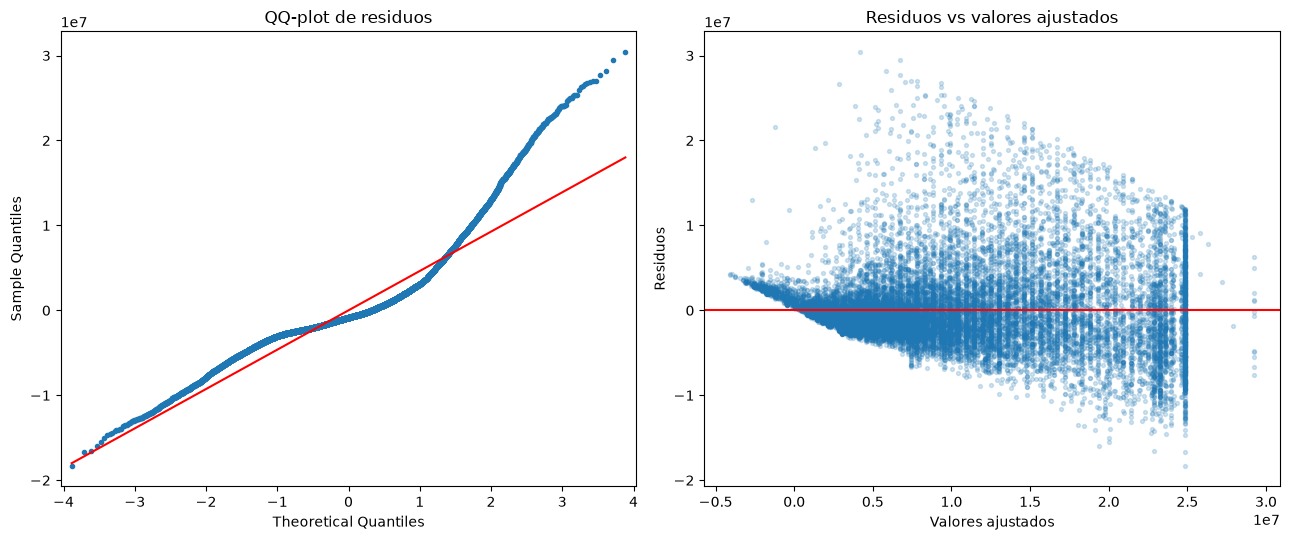

TEST DE NORMALIDAD (Shapiro-Wilk sobre los residuos)
  W = 0.8772 | p-valor = 7.127e-81
  Conclusión: se rechaza la normalidad (alfa = 0,05)

TEST DE HOMOCEDASTICIDAD (Breusch-Pagan)
  LM = 1144.31 | p-valor = 3.588e-219
  Conclusión: se rechaza la homocedasticidad (alfa = 0,05)


d:\Proyectos\Trabajo Fundamentos\TPE_CienciaDeDatos\Azucar\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 19568.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
import matplotlib.pyplot as plt

residuos = modelo.resid
ajustados = modelo.fittedvalues

# --- Gráficos ---
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))

sm.qqplot(residuos, line="s", ax=ax[0], markersize=3)
ax[0].set_title("QQ-plot de residuos")

ax[1].scatter(ajustados, residuos, alpha=0.2, s=8)
ax[1].axhline(0, color="r")
ax[1].set_xlabel("Valores ajustados")
ax[1].set_ylabel("Residuos")
ax[1].set_title("Residuos vs valores ajustados")

plt.tight_layout()
plt.show()

# --- Tests (salida por consola, debajo de los gráficos) ---
W, p_sw = stats.shapiro(residuos)
lm, p_bp, f_stat, p_f = het_breuschpagan(residuos, modelo.model.exog)

print("TEST DE NORMALIDAD (Shapiro-Wilk sobre los residuos)")
print(f"  W = {W:.4f} | p-valor = {p_sw:.3e}")
print(f"  Conclusión: {'se rechaza' if p_sw < 0.05 else 'no se rechaza'} la normalidad (alfa = 0,05)\n")

print("TEST DE HOMOCEDASTICIDAD (Breusch-Pagan)")
print(f"  LM = {lm:.2f} | p-valor = {p_bp:.3e}")
print(f"  Conclusión: {'se rechaza' if p_bp < 0.05 else 'no se rechaza'} la homocedasticidad (alfa = 0,05)")

**Diagnóstico de los supuestos**

- _Normalidad_: el QQ-plot muestra que los residuos se alejan de la línea en las colas, con asimetría positiva (1,41) y colas pesadas (curtosis 7,94). Shapiro-Wilk rechaza la normalidad. 
- _Homocedasticidad_: el gráfico de residuos vs valores ajustados no tiene dispersión pareja, sino que se abre al crecer el valor ajustado. Breusch-Pagan rechaza la homocedasticidad.

Como se violan los dos supuestos la hipótesis se contrasta con **Kruskal-Wallis**.

**seccion 5.6**

In [ ]:
import statsmodels.formula.api as smf
from scipy import stats

# Modelo reducido: sin barrio
reducido = smf.ols(
    "estimated_revenue_l365d ~ estimated_occupancy_l365d + C(room_type)",
    data=df_multi).fit()
df_multi["residuos_reducido"] = reducido.resid

# Kruskal-Wallis: residuos agrupados por barrio
grupos = [g["residuos_reducido"].values
          for _, g in df_multi.groupby("neighbourhood_cleansed")]
H, p = stats.kruskal(*grupos)

k = len(grupos)
n = len(df_multi)
epsilon2 = (H - k + 1) / (n - k)   # tamaño del efecto

print("KRUSKAL-WALLIS (residuos del modelo sin barrio, agrupados por barrio)")
print(f"  Grupos (barrios) = {k} | n = {n}")
print(f"  H = {H:.2f} | gl = {k-1} | p-valor = {p:.3e}")
print(f"  Tamaño del efecto (epsilon²) = {epsilon2:.3f}")
print(f"  Conclusión: {'se rechaza' if p < 0.05 else 'no se rechaza'} H0 (alfa = 0,05)")

**Resultado del contraste**

Kruskal-Wallis sobre los residuos agrupados por 30 barrios (n = 20.331): H = 1053,64; gl = 29; p ≈ 3,9e-203. Como p < 0,05, **se rechaza H0**: a igual ocupación y tipo de habitación, el ingreso anual estimado difiere entre barrios.

**Conclusión**

La evidencia respalda la hipótesis: el barrio influye en el ingreso anual estimado de un alojamiento, incluso descontando el efecto de la ocupación y del tipo de habitación. El tamaño del efecto es pequeño a moderado (epsilon² = 0,050), es decir que el barrio explica una parte acotada de la variación, y la mayor parte la explican la ocupación y el tipo de habitación. En el modelo OLS, los barrios con mayor ingreso respecto de Almagro son Puerto Madero, Palermo, Recoleta, Colegiales y Belgrano.


## 6 potesis multivariada (catedra):


Hipotesis: A igual capacidad de huéspedes, un alojamiento se alquila más caro si garantiza mayor independencia: tener una cama para cada persona, mayor cantidad de baños por huésped, y reserva automática.

### Analisis exploratorio:

**seccion 6.1**

In [100]:
import numpy as np, pandas as pd

n0 = len(preprocessed_dataset)

#Transformacion de la columna bathrooms_text
t = preprocessed_dataset["bathrooms_text"].astype(str).str.lower()

n = t.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)   #nos quedamos con el numero que aparece en el string
es_medio = t.str.contains("half")                          #contamos medio si encontramos la palabra half

#transformamos el es_medio a cantidad de baños que representa
preprocessed_dataset["banos_txt"] = np.where(es_medio, 0.5 * n.fillna(1), n)

#completamos bathrooms con los datos de bathrooms_text
preprocessed_dataset["bathrooms_ok"] = preprocessed_dataset["bathrooms"].fillna(preprocessed_dataset["banos_txt"])

#Eliminamos baños que siguieron siendo nulos despues de la transformacion
preprocessed_dataset = preprocessed_dataset.dropna(subset=["bathrooms_ok"])
n1 = len(preprocessed_dataset)

#sacamos filas con baños=0
preprocessed_dataset = preprocessed_dataset[preprocessed_dataset["bathrooms_ok"] > 0]
n2 = len(preprocessed_dataset)

print("Eliminados por baños nulos:", n0 - n1)
print("Eliminados por 0 baños:", n1 - n2)
print("Nulos en bathrooms_ok:", preprocessed_dataset["bathrooms_ok"].isna().sum())

Eliminados por baños nulos: 18
Eliminados por 0 baños: 127
Nulos en bathrooms_ok: 0


In [101]:
# Queremos saber que coincidencia habia entre ambas variables, asi sabemos si preservamos valores reales
ambas = preprocessed_dataset["bathrooms"].notna() & preprocessed_dataset["banos_txt"].notna()
print("Coinciden:", (preprocessed_dataset.loc[ambas, "bathrooms"] == preprocessed_dataset.loc[ambas, "banos_txt"]).mean())
print(preprocessed_dataset.loc[ambas & (preprocessed_dataset["bathrooms"] != preprocessed_dataset["banos_txt"]),
            ["bathrooms", "bathrooms_text", "banos_txt"]].head(10))


Coinciden: 0.999844973257887
       bathrooms bathrooms_text  banos_txt
8589         1.0      1.5 baths        1.5
10237        1.5      2.5 baths        2.5
19202        1.0        0 baths        0.0
19295        1.0        0 baths        0.0


In [102]:
#Eliminamos nulos en beds
n0 = len(preprocessed_dataset)

preprocessed_dataset = preprocessed_dataset.dropna(subset=["beds"])

print("Eliminados por beds nulos:", n0 - len(preprocessed_dataset))
print("Nulos en beds:", preprocessed_dataset["beds"].isna().sum())

Eliminados por beds nulos: 2435
Nulos en beds: 0


In [103]:
preprocessed_dataset['beds'].value_counts()

beds
1.0     13535
2.0      6807
3.0      3633
4.0      1501
5.0       502
6.0       242
7.0        84
8.0        62
9.0        33
10.0       31
12.0       25
11.0       10
14.0        9
16.0        8
15.0        5
13.0        5
20.0        3
22.0        2
17.0        2
30.0        2
25.0        2
21.0        1
50.0        1
28.0        1
32.0        1
27.0        1
38.0        1
18.0        1
26.0        1
Name: count, dtype: int64

**seccion 6.2**

In [104]:
preprocessed_dataset["beds_per_guest"] = preprocessed_dataset["beds"] / preprocessed_dataset["accommodates"]
preprocessed_dataset["baths_per_guest"] = preprocessed_dataset["bathrooms_ok"] / preprocessed_dataset["accommodates"]

In [105]:
print(preprocessed_dataset["price"].describe())
print(preprocessed_dataset["price"].quantile([.5, .9, .99, .999, 1]))
print(preprocessed_dataset.nlargest(10, "price")[["price", "accommodates", "beds", "bathrooms_ok"]])

count     26511.000000
mean     122957.077304
std       84919.820374
min       23028.940000
25%       76514.670000
50%      100631.330000
75%      138643.450000
max      776253.500000
Name: price, dtype: float64
0.500    100631.330
0.900    205889.320
0.990    503882.302
0.999    724550.600
1.000    776253.500
Name: price, dtype: float64
           price  accommodates  beds  bathrooms_ok
11389  776253.50            14   8.0           5.5
19561  774671.00             6   3.0           5.5
4623   771917.33             2   1.0           1.0
17044  770519.71             8   4.0           4.5
17109  765355.01             2   1.0           1.0
28774  764926.00             8   9.0           4.0
24818  764925.50             2   1.0           1.0
28240  763549.00             4   3.0           2.0
26381  762757.33             4   3.0           2.0
5435   760607.00             3   2.0           1.5


In [115]:
import numpy as np

n0 = len(preprocessed_dataset)

lo, hi = preprocessed_dataset["price"].quantile([.01, .99])
print("Rango conservado:", lo, "-", hi)
#limpiamos outliers y nos quedamos con precios que parecen logicos
preprocessed_dataset = preprocessed_dataset[preprocessed_dataset["price"].between(lo, hi)].copy()

preprocessed_dataset["baths_per_guest"] = preprocessed_dataset["bathrooms_ok"] / preprocessed_dataset["accommodates"]
preprocessed_dataset["beds_per_guest"] = preprocessed_dataset["beds"] >= preprocessed_dataset["accommodates"]


print(n0, "->", len(preprocessed_dataset))
print(preprocessed_dataset["price"].describe())

Rango conservado: 38651.111 - 379667.35150000005
24536 -> 24044
count     24044.000000
mean     116193.217389
std       56024.002214
min       38662.590000
25%       79672.732500
50%      101250.000000
75%      135980.450000
max      379638.290000
Name: price, dtype: float64


**seccion 6.3*

In [117]:
preprocessed_dataset = preprocessed_dataset[preprocessed_dataset['accommodates'].between(2, 6)]
print(len(preprocessed_dataset), len(preprocessed_dataset) / len(preprocessed_dataset))

24044 1.0


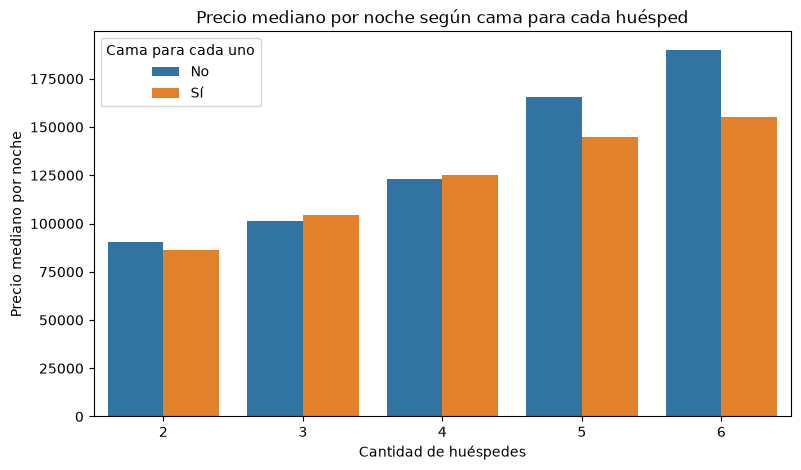

In [116]:
#Grafico que explica mejor la tabla

plt.figure(figsize=(9, 5))
sns.barplot(data=preprocessed_dataset, x='accommodates', y='price_quote_price_per_night',
            hue='beds_per_guest', estimator='median', errorbar=None)
plt.title('Precio mediano por noche según cama para cada huésped')
plt.xlabel('Cantidad de huéspedes')
plt.ylabel('Precio mediano por noche')
plt.legend(title='Cama para cada uno', labels=['No', 'Sí'])
plt.show()

**seccion 6.4**

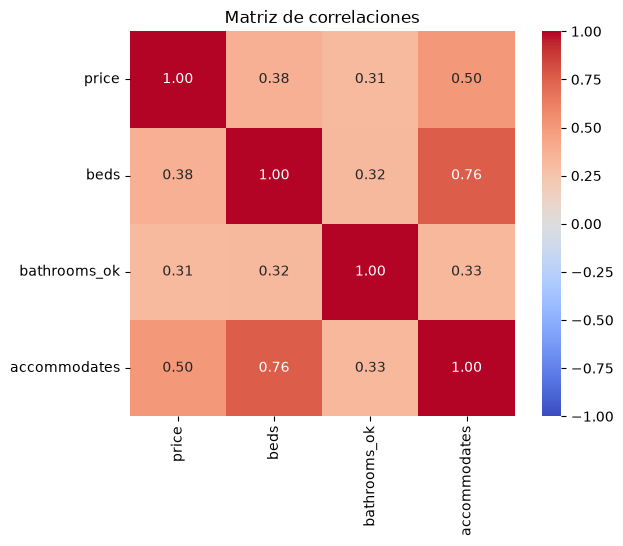

In [107]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["price", "beds", "bathrooms_ok", "accommodates"]
corr = preprocessed_dataset[cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlaciones")
plt.show()

**seccion 6.5**

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
#Variable dependiente
y = preprocessed_dataset['price']
#Variable independiente
X = preprocessed_dataset[['accommodates', 'baths_per_guest', 'beds_per_guest']]

#Estandarizacion de predictores
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

In [ ]:
# Chequeamos que la estandarizacion haya funcionado
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])

print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

### Validacion de hipotesis

Aplicando regresión lineal obtenemos el siguiente resultado:

**seccion 6.6**

In [ ]:
# Agregamos una constante como característica, para estimar la ordenada al origen
import statsmodels.api as sm
X_scaled_df_ = sm.add_constant(X_scaled_df)
# Ajustamos el modelo
model = sm.OLS(y, X_scaled_df_).fit()
# Imprimimos el resumen de los resultados
print(model.summary())

**Seccion 6.7**

Bondad de ajuste: las variables logran explicar solo el 28.6% de la varianza total de price, es un porcentaje bastante bajo, es decir, hay más variables que influyen en el precio y en este modelo no se logra explicar.
Prueba de significancia del modelo: con un valor de F alto y un p-valor menor a cero podemos decir que el modelo es útil para predecir el precio por noche.
Const: representa el valor medio del precio cuando el resto de las variables es 0, en este caso 123600


Accommodates: Por cada unidad adicional en la capacidad de alojamiento de la propiedad, el precio estimado incrementa en aproximadamente $47,750

Baths_per_guest: el aumento de una unidad en la proporción de baños por huésped está asociado con un incremento de $5,346.03 en el precio estimado

Beds_per_guest: en este caso la relación es negativa, indicando que por cada unidad adicional en la relación de camas por huésped, el precio estimado disminuye en unos $2,258.68. Esto pareciera en un principio no tener mucho sentido, pero podríamos pensar que por ejemplo,una mayor cantidad de camas individuales suele ser un indicador indirecto de propiedades de menor categoría o más económicas.
Todos los regresores tienen un p-valor bajo, menor a 0.05, por lo que son estadísticamente significativos


Las pruebas de Omnibus (17,150.81, p < 0.001) y Jarque-Bera (314,221.08, p < 0.001) rechazan la hipótesis de normalidad de los residuos. Dado que Skew = 2.850, podemos saber que presenta una asimetría positiva y una elevada curtosis ,Kurtosis = 18.900, lo que sugiere la existencia de valores atípicos o colas pesadas. El p-valor es bajo para ambos test, menor que 0, lo que nos indica que los residuos no son normales.


In [ ]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm

# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)
# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)
# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()


Esto tambien se evidencia en el histograma de los residuos, podemos ver que no sigue una distribucion perdectamente normal, las colas no son iguales.


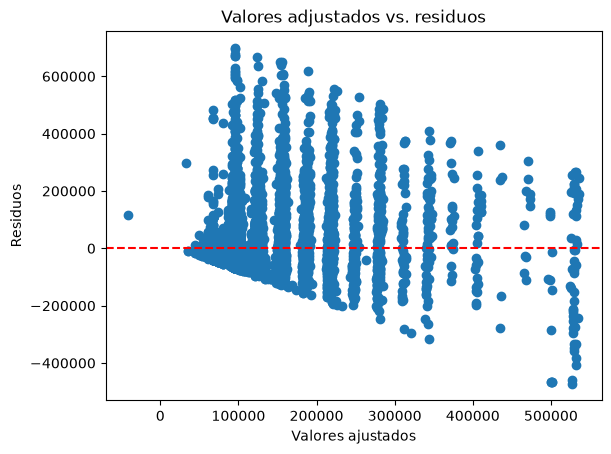

In [ ]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

No se observa un comportamiento en banda alrededor del cero, con valores que traspasan los límites de -3,3

Valor de Durbin-Watson: Nos devolvió 1.678, lo que nos indica que los errores tienen una correlación positiva, es decir tienen una relación.

Que la distribución de los residuales no siga una distribución normal nos hace pensar que la elección de la estructura no captura la complejidad de la variable price.

